# European contract pricing with Tree

In [1]:
import numpy as np
from scipy.optimize import minimize
from collections.abc import Callable

## Create European contract payoff

In [2]:
def european_call_payoff(S: float, K: float) -> float:
    return max(S-K, 0.0)

## Create Spot Tree

In [3]:
def create_spot_tree(spot: float, spot_mult_up: float, spot_mult_down: float, steps: int) -> list[list[float]]:
    previous_level = [spot]
    tree = [previous_level]
    for _ in range(steps):
        new_level = [s * spot_mult_down for s in previous_level]
        new_level += [previous_level[-1] * spot_mult_up]
        tree += [new_level]
        previous_level = new_level
    return tree

In [4]:
spot = 1
spot_mult_up = 1.2
spot_mult_down = 0.8
steps = 2
spot_tree = create_spot_tree(spot, spot_mult_up, spot_mult_down, steps)
spot_tree_readable = [['%.3f' % e for e in n] for n in spot_tree]
spot_tree_readable

[['1.000'], ['0.800', '1.200'], ['0.640', '0.960', '1.440']]

## Create Price Tree

In [5]:
def create_discounted_price_tree(spot_tree: list[list[float]], discount_factor: float, K: float, diag: int = 0) -> list[list[float]]:
    spot = spot_tree[0][0]
    spot_mult_up = spot_tree[1][-1]
    spot_mult_down = spot_tree[1][0]
    p_up = ((1 / discount_factor - spot_mult_down) /
                   (spot_mult_up - spot_mult_down))
    p_down = 1 - p_up
    steps = len(spot_tree) - 1
    continuation_value_tree = [[np.nan for _ in level] for level in spot_tree]
    if diag > 0:
        print("risk-neutral measure: ")
        print(('%.3f' % p_up, '%.3f' % p_down))
        # init delta tree
        delta_tree = [[np.nan for _ in level] for level in spot_tree[:-1]] #delta makes no sense for leaves
    # going backwards, payoff is known in leaves
    for i in range(len(spot_tree[-1])):
        spot = spot_tree[-1][i]
        discounted_continuation_value = discount_factor**(steps) * european_call_payoff(spot, K)
        continuation_value_tree[-1][i] = discounted_continuation_value
    for step in range(steps - 1, -1, -1):
        for i in range(len(spot_tree[step])):
            continuation_value_tree[step][i] = p_up * continuation_value_tree[step + 1][i] + \
                                            p_down * continuation_value_tree[step + 1][i + 1]
            if diag > 0:
                delta_tree[step][i] = ((continuation_value_tree[step + 1][i] - continuation_value_tree[step + 1][i + 1]) 
                                       / (spot_tree[step + 1][i] - spot_tree[step + 1][i + 1]))
    if diag > 0:
        print("delta: ")
        delta_tree_readable = [['%.3f' % e for e in n] for n in delta_tree]
        print(delta_tree_readable)
    return continuation_value_tree

In [6]:
discount_factor = 0.95
strike = 1
diag = 1
price_tree = create_discounted_price_tree(spot_tree, discount_factor, strike, diag)
price_tree_readable = [['%.3f' % e for e in n] for n in price_tree]
print("Price tree:")
price_tree_readable

risk-neutral measure: 
('0.632', '0.368')
delta: 
[['0.366'], ['-0.000', '0.827']]
Price tree:


[['0.054'], ['0.000', '0.146'], ['0.000', '0.000', '0.397']]

In [7]:
pv_up_up = 0.44*0.95*0.95
print('%.3f' % pv_up_up)

0.397


In [8]:
mid_step = 0.3971 * 0.3684210526315791
print('%.3f' % mid_step)

0.146


## Balanced Tree

In [9]:
def calcBalancedDownStep(spot_mult_up: float, discount_factor: float) -> (float, float):
    return spot_mult_up - 2 * (spot_mult_up - 1 / discount_factor)

In [10]:
print("spot_mult_up: " + str('%.3f' %spot_mult_up))
spot_mult_down_balanced = calcBalancedDownStep(spot_mult_up, discount_factor)
print("spot_mult_down: " + str('%.3f' %spot_mult_down_balanced))
spot_tree = create_spot_tree(spot, spot_mult_up, spot_mult_down_balanced, steps)
spot_tree_readable = [['%.3f' % e for e in n] for n in spot_tree]
print("spot_tree: " + str(spot_tree_readable))
price_tree = create_discounted_price_tree(spot_tree, discount_factor, strike, 1)
price_tree_readable = [['%.3f' % e for e in n] for n in price_tree]
print("price tree: " + str(price_tree_readable))

spot_mult_up: 1.200
spot_mult_down: 0.905
spot_tree: [['1.000'], ['0.905', '1.200'], ['0.820', '1.086', '1.440']]
risk-neutral measure: 
('0.500', '0.500')
delta: 
[['0.674'], ['0.292', '0.903']]
price tree: [['0.138'], ['0.039', '0.237'], ['0.000', '0.078', '0.397']]


## Delta is close to 0.5 for At The Money Forward option

In [11]:
strike_ATMF = 1/0.95**2
price_tree = create_discounted_price_tree(spot_tree, discount_factor, strike_ATMF, 1)
price_tree_readable = [['%.3f' % e for e in n] for n in price_tree]
print("price tree:")
price_tree_readable

risk-neutral measure: 
('0.500', '0.500')
delta: 
[['0.508'], ['-0.000', '0.847']]
price tree:


[['0.075'], ['0.000', '0.150'], ['0.000', '0.000', '0.300']]

## Barrier options

In [12]:
def up_and_out(B: float) -> Callable[[float], float]:
    def knock_multiplier(s: float) -> float:
        return 1.0 if (s < B) else 0.0
    return knock_multiplier

In [13]:
def create_discounted_price_tree_ko(spot_tree: list[list[float]], discount_factor: float, K: float, ko_function: Callable[[float], float], diag: int = 0) -> list[list[float]]:
    spot = spot_tree[0][0]
    spot_mult_up = spot_tree[1][-1]
    spot_mult_down = spot_tree[1][0]
    p_up = ((1 / discount_factor - spot_mult_down) /
                   (spot_mult_up - spot_mult_down))
    p_down = 1 - p_up
    steps = len(spot_tree) - 1
    continuation_value_tree = [[np.nan for _ in level] for level in spot_tree]
    if diag > 0:
        print("risk-neutral measure: ")
        print((p_up, p_down))
        # init delta tree
        delta_tree = [[np.nan for _ in level] for level in spot_tree[:-1]] #delta makes no sense for leaves
    # going backwards, payoff is known in leaves
    for i in range(len(spot_tree[-1])):
        spot = spot_tree[-1][i]
        discounted_continuation_value = discount_factor**(steps) * european_call_payoff(spot, K) * ko_function(spot)
        continuation_value_tree[-1][i] = discounted_continuation_value
    for step in range(steps - 1, -1, -1):
        for i in range(len(spot_tree[step])):
            continuation_value_tree[step][i] = p_up * continuation_value_tree[step + 1][i] + \
                                            p_down * continuation_value_tree[step + 1][i + 1]
            continuation_value_tree[step][i] *= ko_function(spot_tree[step][i])
            if diag > 0:
                delta_tree[step][i] = ((continuation_value_tree[step + 1][i] - continuation_value_tree[step + 1][i + 1]) 
                                       / (spot_tree[step + 1][i] - spot_tree[step + 1][i + 1]))
                delta_tree[step][i] *= ko_function(spot_tree[step][i])
    if diag > 0:
        print("delta: ")
        delta_tree_readable = [['%.3f' % e for e in n] for n in delta_tree]
        print(delta_tree_readable)
    return continuation_value_tree

In [14]:
# create spot tree
spot = 1
maturity = 1 # years
steps_per_year = 7
steps = steps_per_year * maturity
discount_factor = 0.95 ** (1./steps_per_year) # discount factors have to be scaled to keep interest rate fixed
spot_mult_up = np.exp((0.05 - 0.5 * 0.1 ** 2) / steps_per_year + 0.1 * np.sqrt(1./steps_per_year)) # step sizes are scaled as well
spot_mult_down = calcBalancedDownStep(spot_mult_up, discount_factor)
spot_tree = create_spot_tree(spot, spot_mult_up, spot_mult_down, steps)
spot_tree_readable = [['%.3f' % e for e in n] for n in spot_tree]
spot_tree_readable

[['1.000'],
 ['0.969', '1.045'],
 ['0.940', '1.013', '1.092'],
 ['0.911', '0.982', '1.059', '1.142'],
 ['0.883', '0.952', '1.027', '1.107', '1.194'],
 ['0.856', '0.923', '0.996', '1.073', '1.157', '1.247'],
 ['0.830', '0.895', '0.965', '1.041', '1.122', '1.209', '1.304'],
 ['0.805', '0.868', '0.936', '1.009', '1.088', '1.173', '1.264', '1.363']]

In [15]:
# create price tree
strike = 1
barrier = 1.2
barrier_condition = up_and_out(barrier)
diag = 1
price_tree = create_discounted_price_tree_ko(spot_tree, discount_factor, strike, barrier_condition, diag)
price_tree_readable = [['%.3f' % e for e in n] for n in price_tree]
print("Price tree:")
price_tree_readable

risk-neutral measure: 
(0.5, 0.5)
delta: 
[['0.246'], ['0.386', '0.113'], ['0.378', '0.389', '-0.145'], ['0.181', '0.555', '0.229', '-0.490'], ['0.031', '0.317', '0.768', '-0.273', '-0.683'], ['-0.000', '0.060', '0.552', '0.957', '-1.410', '-0.000'], ['-0.000', '-0.000', '0.114', '0.950', '0.950', '-0.000', '-0.000']]
Price tree:


[['0.044'],
 ['0.035', '0.054'],
 ['0.021', '0.049', '0.058'],
 ['0.007', '0.034', '0.064', '0.052'],
 ['0.001', '0.014', '0.055', '0.073', '0.031'],
 ['0.000', '0.002', '0.025', '0.085', '0.062', '0.000'],
 ['0.000', '0.000', '0.004', '0.046', '0.124', '0.000', '0.000'],
 ['0.000', '0.000', '0.000', '0.008', '0.083', '0.164', '0.000', '0.000']]

## Q: How would you model continuous barrier better?

# Homework Assignment 
## Calibrator

In [18]:
from scipy.optimize import minimize
from scipy.stats import norm
import numpy as np

In [19]:
def calibrator(target_price: float, S: float, K: float, df: float, steps: int) -> list[list[float]]:    
    def error_function(U):
        U = U[0]
        D = calcBalancedDownStep(U, df)
        #build trees with given U and D
        spot_tree = create_spot_tree(spot, U, D, steps) #nodes are spot prices
        price_tree = create_discounted_price_tree(spot_tree, df, K) #nodes are V: option values
        tree_price = price_tree[0][0]
        return (tree_price - target_price) ** 2 # the squared error
        
    result = minimize(error_function, x0=[1.1], method='Nelder-Mead') # the initial value 1.1 and the choosen method were recommended by Claude
    
    calibrated_U = result.x[0]
    return calibrated_U

### Checking calibrator

In [21]:
import matplotlib.pyplot as plt
from matplotlib import rcParams # detailed parameter setting
""" more details on customization: https://matplotlib.org/stable/tutorials/introductory/customizing.html """
from typing import Dict, List, Union


def my_plotter(x: List[float], y: Union[List[float], List[List[float]]], layout: Dict = {}, names: List[str] = None, colors = None , linestyles = None) -> None:
    """ inline for loop is called 'list comprehension' """
    y = [y] if all(isinstance(item, float) for item in y) else y
    
    plt.figure(figsize=layout.get('figsize', (8, 4))) #replaced prev line
    lines = []
    show_legend = True if names is not None else False
    # show_legend = True if names else False  -> here is fine, but be cautious bc 0, empty str and empty list will be evaulated to False

    """ setup some basic key-word arguments for plot line """
    plot_kwargs = {
        'linestyle': layout.get('linestyle', 'solid'), #added
        'linewidth': layout.get('linewidth', 4) #added
    }
    if names is not None:
        show_legend = True
        if len(names) != len(y):
            raise ValueError("Length of names is not matching with number of plotted y lists.")

    """ 'enumerate' add a counter to the loop """
    for i, y_item in enumerate(y):
        if show_legend:
            plot_kwargs['label'] = names[i]
        if colors is not None:
            plot_kwargs['color'] = colors[i] #added
        if linestyles is not None:
            plot_kwargs['linestyle'] = linestyles[i]

        _line = plt.plot(x, y_item, **plot_kwargs)
        lines.append(_line)

    if show_legend:
        plt.legend(fontsize=layout.get('legend_fontsize', 16),loc=layout.get('legend_loc', 'best'))

    if 'title' in layout:
        plt.title(layout['title'], fontsize=layout.get('title_fontsize', 20))
        rcParams['axes.titlepad'] = layout.get('titlepad', 30)
    if 'x_label' in layout:
        plt.xlabel(layout['x_label'], fontsize=layout.get('label_fontsize', 16))
        rcParams['axes.labelpad'] = layout.get('labelpad', 20)
    if 'y_label' in layout:
        plt.ylabel(layout['y_label'], fontsize=layout.get('label_fontsize', 16))
   

    """ enhance axes """
    ax = plt.gca() # gca: get current axes
    ax.axhline(linestyle='--', color='black', linewidth=1)
    plt.show()

BSM price: 0.104506
Steps=  1 | U=1.219722 | D=0.882821 | Tree price=0.104503
Steps=  2 | U=1.175625 | D=0.875005 | Tree price=0.104504
Steps=  3 | U=1.125835 | D=0.907778 | Tree price=0.104497
Steps=  5 | U=1.096777 | D=0.923323 | Tree price=0.104488
Steps=  7 | U=1.081362 | D=0.932975 | Tree price=0.104521
Steps= 10 | U=1.067827 | D=0.942198 | Tree price=0.104508
Steps= 15 | U=1.054829 | D=0.951849 | Tree price=0.104516
Steps= 20 | U=1.046880 | D=0.958126 | Tree price=0.104510
Steps= 30 | U=1.037964 | D=0.965372 | Tree price=0.104541
Steps= 50 | U=1.029155 | D=0.972846 | Tree price=0.104474


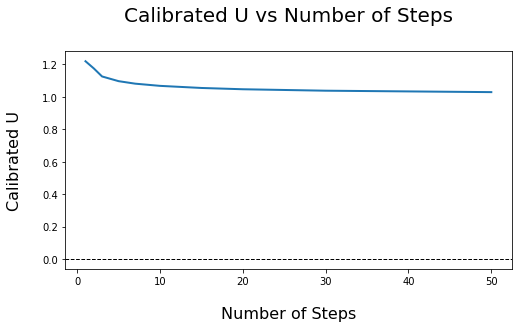

In [33]:
# wrt number of steps
spot = 1.0
K = 1.0
r = 0.05
T = 1.0
sigma = 0.2

bsm_price = black_scholes_eur_call(r, T, spot, sigma, K)
print(f"BSM price: {bsm_price:.6f}")

# same contract with few different number of steps
steps_list = [1, 2, 3, 5, 7, 10, 15, 20, 30, 50]
calibrated_U_list = []

for steps in steps_list:
    df_per_step = np.exp(-r * T / steps)  # scale df
    U = calibrator(bsm_price, spot, K, df_per_step, steps)
    calibrated_U_list.append(U)
    
    # Verify
    D = calcBalancedDownStep(U, df_per_step)
    spot_tree = create_spot_tree(spot, U, D, steps)
    price_tree = create_discounted_price_tree(spot_tree, df_per_step, K)
    tree_price = price_tree[0][0]
    print(f"Steps={steps:3d} | U={U:.6f} | D={D:.6f} | Tree price={tree_price:.6f}")

# Plot: calibrated U vs number of steps
x_plot = [float(s) for s in steps_list]
y_plot = calibrated_U_list

my_plotter(x_plot, y_plot, layout={
    'title': 'Calibrated U vs Number of Steps',
    'x_label': 'Number of Steps',
    'y_label': 'Calibrated U',
    'linewidth': 2
})

K=0.70 | BSM price=0.335401 | Calibrated U=1.155000
K=0.75 | BSM price=0.289744 | Calibrated U=1.106875
K=0.80 | BSM price=0.245888 | Calibrated U=1.155000
K=0.85 | BSM price=0.204693 | Calibrated U=1.100000
K=0.90 | BSM price=0.166994 | Calibrated U=1.100000
K=0.95 | BSM price=0.133465 | Calibrated U=1.230625
K=1.00 | BSM price=0.104506 | Calibrated U=1.219722
K=1.05 | BSM price=0.080214 | Calibrated U=1.218647
K=1.10 | BSM price=0.060401 | Calibrated U=1.226973
K=1.15 | BSM price=0.044666 | Calibrated U=1.243892
K=1.20 | BSM price=0.032475 | Calibrated U=1.100000
K=1.25 | BSM price=0.023243 | Calibrated U=1.100000
K=1.30 | BSM price=0.016396 | Calibrated U=1.100000
K=1.35 | BSM price=0.011414 | Calibrated U=1.100000


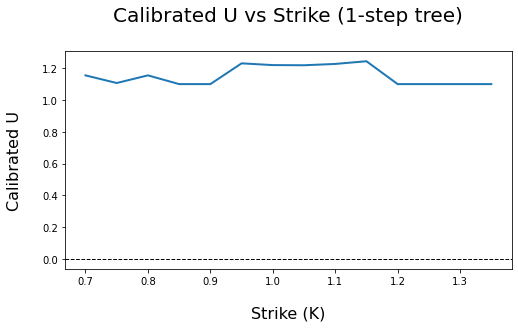

In [31]:
# Different strikes, 1-step tree
strikes = [float(k) for k in np.arange(0.7, 1.35, 0.05)]
calibrated_U_strikes = []

steps = 1
df = np.exp(-r * T / steps)

for K_val in strikes:
    bsm_p = black_scholes_eur_call(r, T, spot, sigma, K_val)
    U = calibrator(bsm_p, spot, K_val, df, steps)
    calibrated_U_strikes.append(U)
    print(f"K={K_val:.2f} | BSM price={bsm_p:.6f} | Calibrated U={U:.6f}")

my_plotter(strikes, calibrated_U_strikes, layout={
    'title': 'Calibrated U vs Strike (1-step tree)',
    'x_label': 'Strike (K)',
    'y_label': 'Calibrated U',
    'linewidth': 2
})

T=0.25 | BSM price=0.046150 | Calibrated U=1.093447
T=0.50 | BSM price=0.068887 | Calibrated U=1.141250
T=0.75 | BSM price=0.087723 | Calibrated U=1.182124
T=1.00 | BSM price=0.104506 | Calibrated U=1.219722
T=1.25 | BSM price=0.119952 | Calibrated U=1.255386
T=1.50 | BSM price=0.134429 | Calibrated U=1.100000
T=1.75 | BSM price=0.148154 | Calibrated U=1.323384
T=2.00 | BSM price=0.161268 | Calibrated U=1.113750
T=2.25 | BSM price=0.173870 | Calibrated U=1.100000
T=2.50 | BSM price=0.186033 | Calibrated U=0.844712
T=2.75 | BSM price=0.197810 | Calibrated U=1.100000
T=3.00 | BSM price=0.209244 | Calibrated U=1.100000


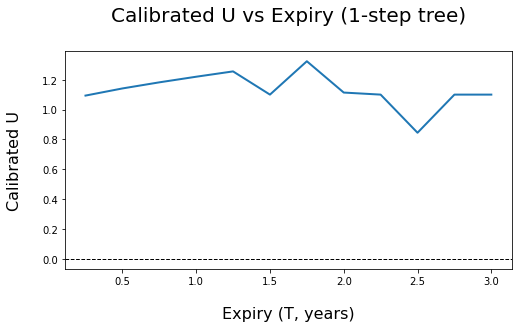

In [32]:
# Different expiries, 1-step tree
expiries = [float(t) for t in np.arange(0.25, 3.25, 0.25)]
calibrated_U_expiries = []

steps = 1

for T_val in expiries:
    df = np.exp(-r * T_val / steps) #flatinterestrate
    bsm_p = black_scholes_eur_call(r, T_val, spot, sigma, K)
    U = calibrator(bsm_p, spot, K, df, steps)
    calibrated_U_expiries.append(U)
    print(f"T={T_val:.2f} | BSM price={bsm_p:.6f} | Calibrated U={U:.6f}")

my_plotter(expiries, calibrated_U_expiries, layout={
    'title': 'Calibrated U vs Expiry (1-step tree)',
    'x_label': 'Expiry (T, years)',
    'y_label': 'Calibrated U',
    'linewidth': 2
})